# 04 · Fenómeno 4: el programa de laminación como experimento no diseñado
**Pregunta.** ¿La posición del rollo en el programa (`Secuencia`) se asocia con su resultado, y cuánto de esa asociación es en realidad el producto que se programa en cada posición?

**Por qué importa.** La posición podría aproximar el desgaste de los rodillos. Pero los programas se ordenan por ancho a propósito, así que la posición también arrastra el producto. Además, los rollos de un mismo programa comparten rodillos y campaña: no son observaciones independientes.

**Método.** Comparamos cada resultado **sin ajuste** y **dentro de producto** (restando la media de cada producto). Si la curva se aplana dentro de producto, el patrón era mezcla de producto, no desgaste.

## 0. Configuración
Importa `src/ternium.py`, donde viven la carga de datos y las reglas de limpieza. Basta con tener el repositorio clonado: los Excel ya vienen en `data/`.

In [29]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [30]:
# Configuración: busca la carpeta del repo para poder importar src/ternium.py.
import sys
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ternium import *

estilo()
pd.set_option('display.max_columns', 20)

In [31]:
df = aplicar_reglas(cargar_mc4())
df['OxRod'] = tiene_defecto(df, 'ÓXIDO DE RODILLOS')   # defecto de inspector asociado al estado de los rodillos
df['Posicion'] = pd.cut(df.Secuencia, [0, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 200])

# Aquí el producto incluye el rango de ancho, porque el programa se ordena por ancho.
df['RangoAncho'] = pd.cut(df.Ancho, [0, 1000, 1200, 1400, 1600, 2000]).astype(str)
df['ProdAncho'] = df.Producto + ' | ' + df.RangoAncho

print(f"{df.Programa.nunique():,} programas · mediana de {df.groupby('Programa').size().median():.0f} rollos por programa")

1,834 programas · mediana de 64 rollos por programa


## 1. ¿`Cambio Rodillo Trabajo` marca de verdad un cambio de rodillos?
Si fuera literal, diría "Cambio" casi solo en el primer rollo de cada programa.

In [32]:
t = pd.crosstab(df.Secuencia.clip(upper=10), df['Cambio Rodillo Trabajo'])
t.index = [str(int(i)) if i < 10 else '10 o más' for i in t.index]
t.index.name = 'Secuencia'
print(f"'Cambio' en {(df['Cambio Rodillo Trabajo'] == 'Cambio').mean():.0%} de todos los rollos")
t

'Cambio' en 77% de todos los rollos


Cambio Rodillo Trabajo,Cambio,Sin Cambio
Secuencia,,
1,2623,1392
2,1464,1219
3,1687,878
4,1836,692
5,1826,577
6,1989,584
7,2064,590
8,2308,594
9,2430,662


**Qué vemos.** Dice "Cambio" en 77% de los rollos, incluso después del décimo, y "Sin Cambio" en más de mil primeros rollos. No puede leerse como cambio de rodillos. Queda como pregunta para Ternium y no se usa como medida de desgaste.

## 2. Perfil por posición en el programa

In [33]:
df.groupby('Posicion', observed=True).agg(
    rollos=('Ancho', 'size'),
    ancho_mm=('Ancho', 'median'),
    oxido_rodillos=('OxRod', 'mean'),
    corona_um=('corC', 'mean'),
).round({'ancho_mm': 0, 'oxido_rodillos': 3, 'corona_um': 1})

,rollos,ancho_mm,oxido_rodillos,corona_um
Posicion,,,,
"(0, 5]",14194,1258.0,0.017,64.7
"(5, 10]",14193,1513.0,0.016,66.8
"(10, 20]",31416,1513.0,0.028,75.1
"(20, 30]",28087,1292.0,0.055,68.7
"(30, 40]",21018,1237.0,0.060,66.5
"(40, 50]",15946,1174.0,0.073,66.0
"(50, 60]",12439,1074.0,0.092,64.6
"(60, 70]",7631,985.0,0.100,62.5
"(70, 80]",3341,954.0,0.147,60.4


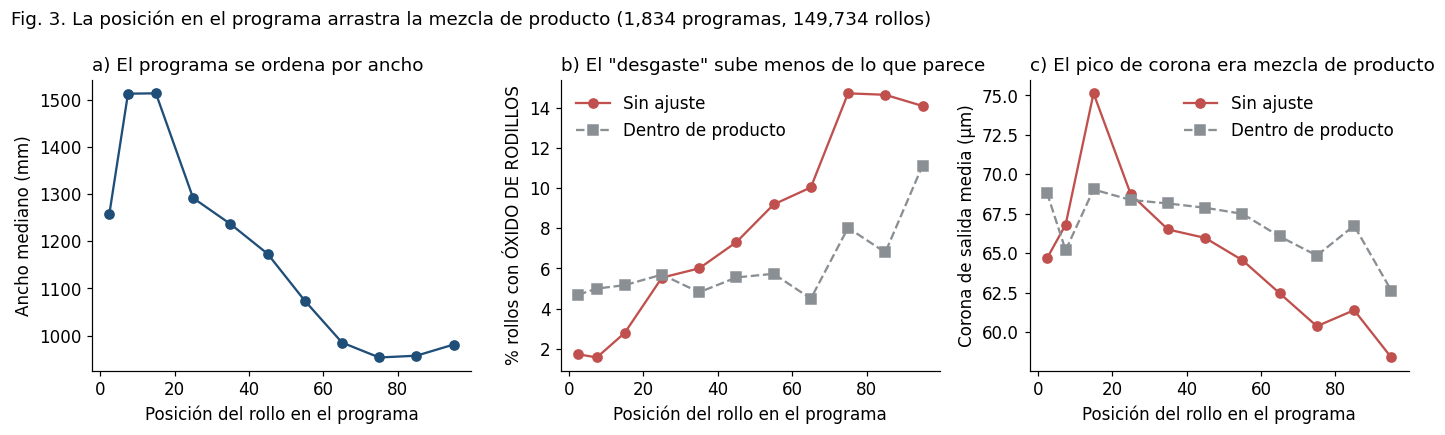

In [34]:
centro = {b: (b.left + min(b.right, 100)) / 2 for b in df.Posicion.cat.categories}
df['x'] = df.Posicion.map(centro).astype(float)

def dentro_de_producto(col, datos):
    """Resta la media de cada producto y suma la media global: quita el efecto de la mezcla."""
    ajust = datos[col] - datos.groupby('ProdAncho')[col].transform('mean') + datos[col].mean()
    return ajust.groupby(datos.x).mean()

bruto = df.groupby('x').agg(ancho=('Ancho', 'median'), ox=('OxRod', 'mean'))
cor = df.dropna(subset=['corC'])

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].plot(bruto.index, bruto.ancho, 'o-', color=COLORES['azul'])
ax[0].set_ylabel('Ancho mediano (mm)')
ax[0].set_title('a) El programa se ordena por ancho')

ax[1].plot(bruto.index, bruto.ox * 100, 'o-', color=COLORES['rojo'], label='Sin ajuste')
ax[1].plot(dentro_de_producto('OxRod', df).mul(100), 's--', color=COLORES['gris'], label='Dentro de producto')
ax[1].set_ylabel('% rollos con ÓXIDO DE RODILLOS')
ax[1].set_title('b) El "desgaste" sube menos de lo que parece')
ax[1].legend()

ax[2].plot(cor.groupby('x').corC.mean(), 'o-', color=COLORES['rojo'], label='Sin ajuste')
ax[2].plot(dentro_de_producto('corC', cor), 's--', color=COLORES['gris'], label='Dentro de producto')
ax[2].set_ylabel('Corona de salida media (µm)')
ax[2].set_title('c) El pico de corona era mezcla de producto')
ax[2].legend()

for a in ax:
    a.set_xlabel('Posición del rollo en el programa')
fig.suptitle(f'Fig. 3. La posición en el programa arrastra la mezcla de producto '
             f'({df.Programa.nunique():,} programas, {len(df):,} rollos)', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
guardar(fig, 'fig3_programa')
plt.show()

**Cómo leerla.** Rojo: el promedio tal cual por posición. Gris: el mismo promedio después de quitar la diferencia entre productos. Si las dos líneas se separan, el patrón rojo se debía a qué producto se programa en esa posición.

**Qué vemos.**
- **a)** El ancho sube de unos 1,260 mm al inicio a 1,510 mm entre los rollos 6 y 20, y baja a menos de 1,000 mm al final: es la forma de "ataúd" deliberada del programa.
- **b)** El óxido de rodillos sube de 2% a casi 15% sin ajuste, pero dentro de producto se mantiene en 4.5% a 5.7% hasta el rollo 70 y solo sube al final. La mayor parte del aumento era mezcla de producto.
- **c)** El pico de corona en los rollos 11 a 20 desaparece dentro de producto; queda una caída suave de unos 69 a 63 µm.

## 3. ¿Cuánto de la corona explica cada agrupación?
Solo rollos con destino al Skinpass y corona válida.

In [35]:
s4 = df[df.SKP & df.corC.notna()]
pd.Series({
    'Producto (con ancho)': r2_por_grupo(s4.corC, s4.ProdAncho),
    'Posición en el programa': r2_por_grupo(s4.corC, s4.Posicion.astype(str)),
    'Programa': r2_por_grupo(s4.corC, s4.Programa),
}, name='fracción de la variación de corona').round(3).to_frame()

,fracción de la variación de corona
Producto (con ancho),0.214
Posición en el programa,0.015
Programa,0.451


**Qué vemos.** La posición explica 1.5% de la variación de la corona; el producto, alrededor de una cuarta parte, y el programa, 45%. Los rollos de un mismo programa se parecen mucho entre sí porque comparten rodillos, horno y campaña.

## Implicaciones para el análisis
1. La `Secuencia` no es una medida limpia de desgaste: es una variable de programación que arrastra ancho y producto.
2. **El programa es la unidad de agrupamiento.** Los errores estándar se agrupan por programa y la validación se parte por programa, nunca al azar por rollo.
3. Como la posición explica poco una vez controlado el producto, una pregunta que reparte la corona entre temperatura y posición tendrá una respuesta casi vacía.
4. `Cambio Rodillo Trabajo` y el significado exacto de `Secuencia` deben confirmarse con Ternium.